## Test Grid SANOS



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
00: Surface 2025-05-06: Fitting 0.25-smooth SANOS to 3168 strikes... done; median error is 0.24 half-spreads for the 20.4% of options which were not fitted within the bid-ask spread. This took 15s.
01:   Surface 2025-05-06 expiry #7 252.0d: Generating extended strikes... done. This took 0.075s.nerating extended strikes... 
00: Training 0.25-smooth SANOS on NMS (-2, 2) grid... done; median absolute NMS vol fit error is 6.823e-06 [FYI median surfacre error 0.24 half-spreads for the 20.4% of options which were not fitted within the bid-ask spread; this model was not trained on the surface] This took 0.13s.


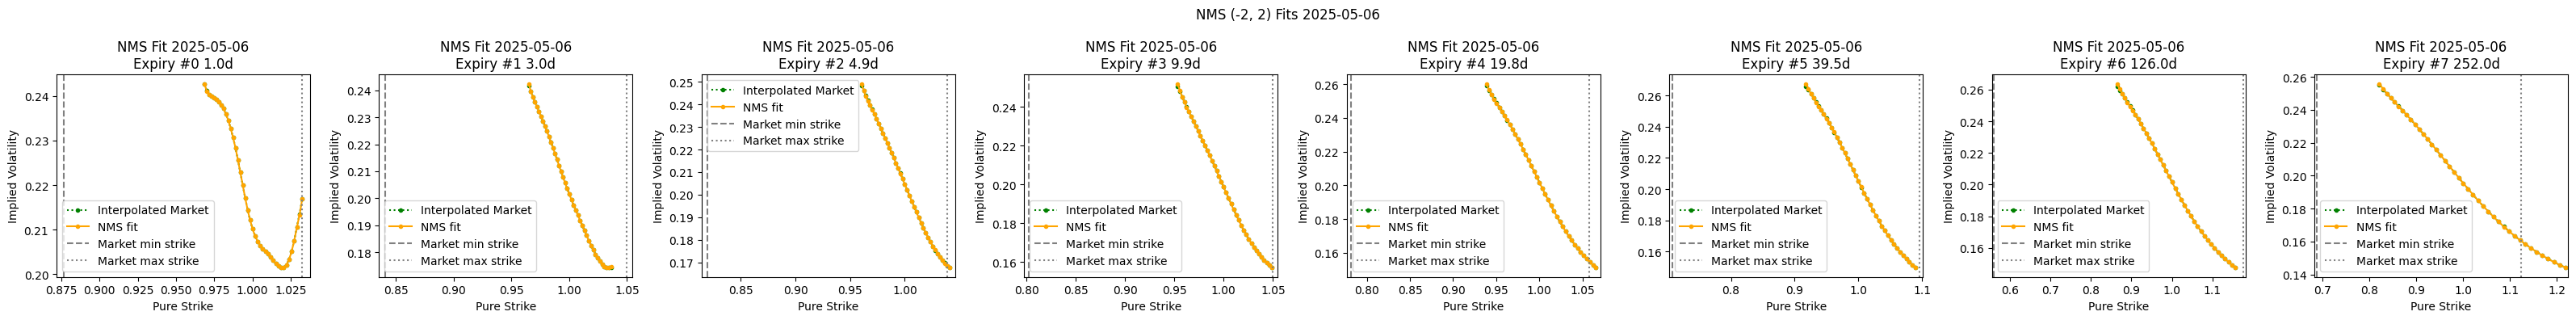

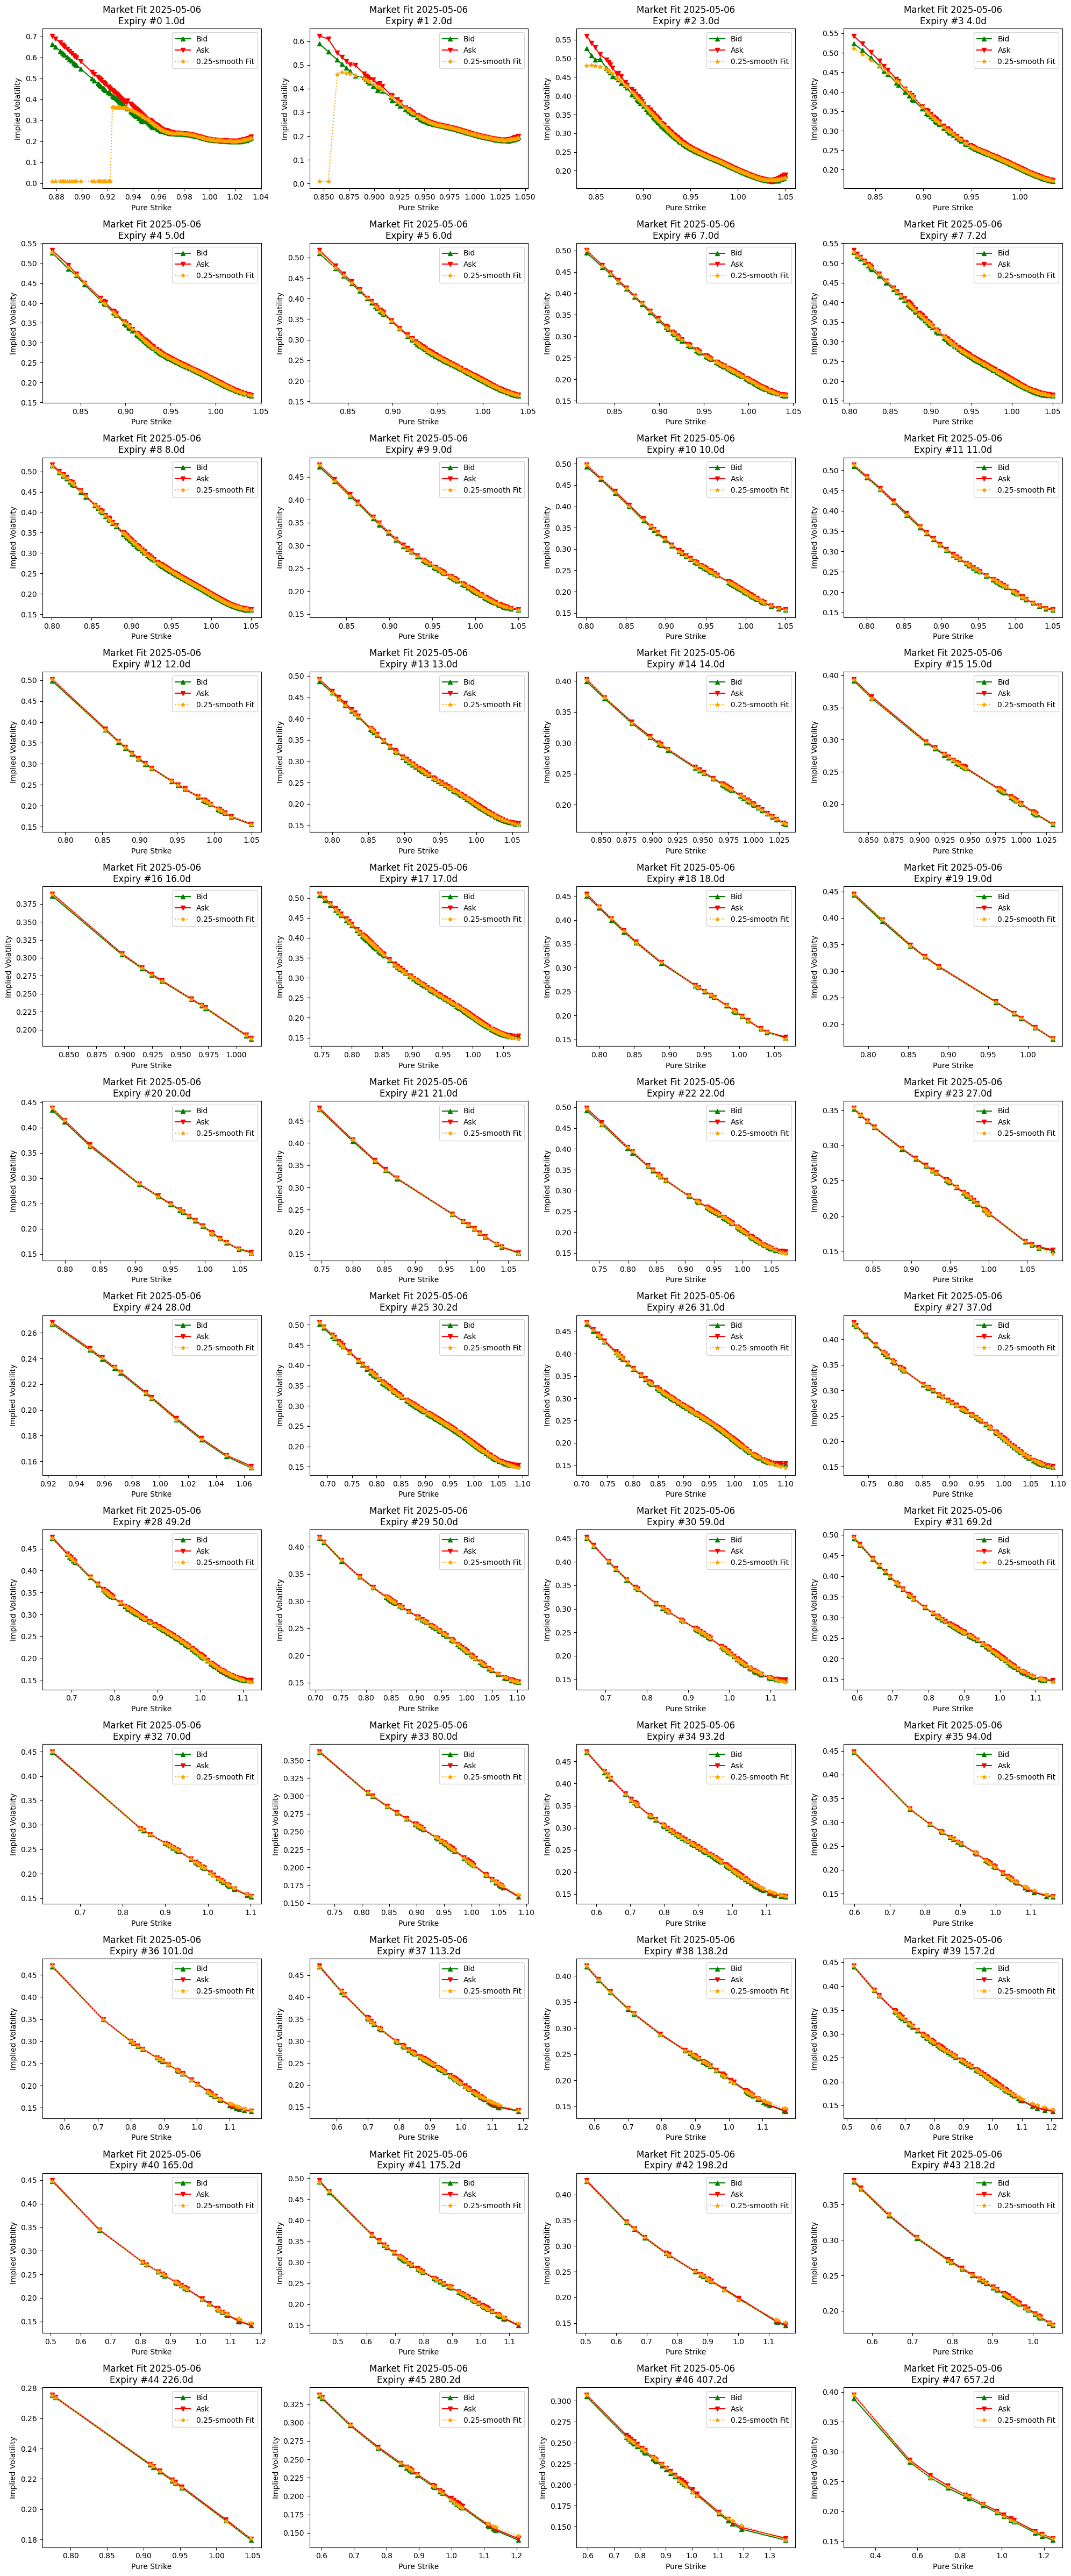

In [ ]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.utils.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.utils.sanos

import math

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, colors_tableau
from cdxcore.verbose import Context
from cdxcore.version import version
from scipy.stats import norm
from quantdata.biz_calendar import DAYS_PER_YEAR, to_date, NMS5
from cdxcore.pretty import PrettyObject
import numpy as np
from dataclasses import dataclass, field    
import warnings
import scipy as scipy
from collections.abc import Callable

from quantdata.utils.sanos import SanosFitter
from quantdata.sanos.arbfree import MkArbFree

DEFAULT_EXPIRIES = np.array([1./255., 3./255., 5./255., 10./255., 20./255., 40./255.,0.5,1.], dtype=np.float64)
DEFAULT_NUMS     = (-2,2)

@version("0.1")
@dataclass(frozen=True)
class SanosBenchmarkConfig:
    smoothness     : float = 0.1
    grid_expiries  : np.array = field( default_factory=lambda: DEFAULT_EXPIRIES )
    grid_nms       : tuple = DEFAULT_NUMS
    grid_num_nms   : int = 100
    vol_spread_fac : float = 1.01
    quantile_range : float = 0.01
    num_qnt_strikes: int = 100

    def _generate_grid_nms(self):
        dist = float(self.grid_nms[1] - self.grid_nms[0])
        Nlo  = min(max(2, float(self.grid_num_nms*abs(self.grid_nms[0]))//dist),self.grid_num_nms-3)
        Nhi = self.grid_num_nms - Nlo - 1

        assert Nlo>=2 and Nhi>=2, f"Internal error: error {Nlo} {Nhi} for grid_nms {self.grid_nms} and grid_num_nms {self.grid_num_nms}."
        grid_nms = np.concatenate( ( np.linspace(self.grid_nms[0], 0., int(Nlo), endpoint=False), np.linspace(0., self.grid_nms[1], int(Nhi)+1) ) )
        assert len(grid_nms)==self.grid_num_nms, f"Internal error: generated number of moneyness levels {len(grid_nms)} does not match expected {self.grid_num_nms} for grid_nms {self.grid_nms} and grid_num_nms {self.grid_num_nms}."
        return grid_nms

    def __call__( self, market, *, message_context : Callable|str|None = None, verbose = Context.all ):

        def message(with_cols : bool = True) -> str:
            if message_context is None:
                return ""
            if callable(message_context):
                msg = message_context()
            else:
                msg = str(message_context)
            if msg == "":
                return msg
            msg = msg[0].upper() + msg[1:]
            return msg if not with_cols else msg + ": "

        assert set(market) >= {'expiries', 'strikes', 'bids', 'asks'}, f"Expected market to have keys 'expiries', 'strikes', 'bids', 'asks' but found {set(market)}"

        str_smth = f"{self.smoothness:.2f}-smooth" if self.smoothness is not None else "linear"

        # fit a smooth SANOS model to the market
        # --------------------------------------

        def compute_market_fit( pricer : callable ) -> PrettyObject:
            r = PrettyObject()
            r.fits = []
            r.fit_vols = []
            r.fit_errs = []
            for t, expiry in enumerate(market.expiries):
                f,v = af_output.price( expiry, market.strikes[t], and_vols=True )
                r.fits.append(f)
                r.fit_vols.append(v)
                spreads = np.maximum( 0.5*(market.asks[t] -market.bids[t]), mk_arb_free.min_half_spread )
                fit_err = (np.maximum( 0., f - market.asks[t] ) + np.maximum(0., market.bids[t] - f) ) / spreads
                r.fit_errs.append(fit_err)

            fit_errors        = np.concatenate(r.fit_errs)
            r.pcnt_fit        = float(np.sum(fit_errors > 0.)) / float(len(fit_errors))
            r.median_fit_err  = np.median(fit_errors[fit_errors>0.] ) if np.any(fit_errors>0.) else 0.
            return r

        with verbose.write_t(lambda : f"\r{message()}Fitting {str_smth} SANOS to {sum( len(s) for s in market.strikes )} strikes... ", end="") as tme:
            mk_arb_free  = MkArbFree(smoothness=self.smoothness, surface_expiry_linear=True )
            af_output    = mk_arb_free( strikes = market.strikes, expiries = market.expiries, bids = market.bids, asks = market.asks, verbose=verbose.quiet )
            fit_result   = compute_market_fit( lambda expiry, strikes : af_output.price( expiry, strikes, and_vols=True, mode="expiry" ) )
            verbose.write(f"done; median error is {fit_result.median_fit_err:.2f} half-spreads for the {fit_result.pcnt_fit*100:.1f}% of options which were not fitted within the bid-ask spread. This took {tme}.", head=False )

        # NMS grid
        # --------

        nms_grid = PrettyObject()

        with verbose.write_t(lambda : f"\rTraining {str_smth} SANOS on NMS {self.grid_nms} grid... ", end="") as tme:
            if self.grid_expiries[-1] > market.expiries[-1]:
                warnings.warn(f"{message()}Warning {str_smth} SANOS: the maximum grid expiry {self.grid_expiries[-1]:.4g} is greater than the maximum market expiry {market.expiries[-1]:.4g}.")

            M                   = len( self.grid_expiries )
            nms_grid.nms        = self._generate_grid_nms()
            nms_grid.expiries   = np.asarray( self.grid_expiries )
            nms_grid.atms       = af_output.interpolate_atm_vols( nms_grid.expiries )
            assert np.all(np.isfinite(nms_grid.atms)), f"Internal error: generated non-finite ATM vols {nms_grid.atms} for grid expiries {nms_grid.expiries} from input expiries {af_output.expiries} and variances {af_output.variances}."

            nms_grid.strikes    = NMS5.from_nms( z=nms_grid.nms[None,:], t=nms_grid.expiries[:,None], vol=nms_grid.atms[:,None] )
            nms_grid.mids,\
            nms_grid.mid_vols   = af_output.price( expiries=nms_grid.expiries[:,None], strikes=nms_grid.strikes, and_vols=True, mode="surface" )
            nms_grid.xstrikes   = np.zeros((M,self.grid_num_nms+2), dtype=nms_grid.strikes.dtype)
            nms_grid.xstrikes[:,1:-1] = nms_grid.strikes
            nms_grid.xstrikes[:,0]   = nms_grid.strikes[:,0]/2.
            nms_grid.xstrikes[:,-1]  = nms_grid.strikes[:,-1]*1.5

            # fit and price market
            sanos           = SanosFitter(smoothness=self.smoothness )
            sn_grid         = sanos(    expiries = nms_grid.expiries, 
                                        strikes  = [ nms_grid.strikes[t,:] for t in range(M) ],
                                        mids     = [ nms_grid.mids[t,:] for t in range(M) ], 
                                        xstrikes = [ nms_grid.xstrikes[t,:] for t in range(M) ],
                                        vols     = nms_grid.atms,
                                        message_context = lambda : message(with_cols=False),
                                        verbose=verbose(1)) 


            nms_grid.fits,\
            nms_grid.fit_vols = sn_grid( expiries=nms_grid.expiries[:,None], strikes=nms_grid.strikes, and_vols=True )
            nms_grid.median_vol_err = np.median( np.abs(nms_grid.fit_vols - nms_grid.mid_vols) )

            nms_fit_result   = compute_market_fit( lambda expiry, strikes : sn_grid.price( expiry, strikes, and_vols=True ) )
            nms_grid.market_fits = nms_fit_result.fits
            nms_grid.market_fit_vols = nms_fit_result.fit_vols
            nms_grid.market_fit_errs = nms_fit_result.fit_errs
            nms_grid.market_fit_pcnt = nms_fit_result.pcnt_fit
            nms_grid.market_fit_median_err = nms_fit_result.median_fit_err
            verbose.write(f"done; median absolute NMS vol fit error is {nms_grid.median_vol_err:.4g} [FYI median surfacre error {nms_fit_result.median_fit_err:.2f} half-spreads for the {nms_fit_result.pcnt_fit*100:.1f}% of options which were not fitted within the bid-ask spread; this model was not trained on the surface] This took {tme}.", head=False )

        return fit_result, nms_grid

from quantdata.widb.options_filter import MkArbFree, RawDayFilter, ExpiryFilter, OptionsFilter, filter_options_day

def assess_fit(d, ticker = "SPX", show_fit : bool = True ):
    d = to_date(d)
    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    mk_arb_free = MkArbFree()
    options_filter = OptionsFilter(max_num_options=100000)

    data = filter_options_day(ticker,d, mk_arb_free=mk_arb_free, options_filter=options_filter, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=Context.all )

    strikes = data['pure_strike'].to_numpy()
    tte_y   = data['tte_y'].to_numpy()
    bid_vol = data['bid_vol'].to_numpy()
    ask_vol = data['ask_vol'].to_numpy()
    fit_vol = data['fit1_vol'].to_numpy()
    bid     = data['pure_bid_price'].to_numpy()
    ask     = data['pure_ask_price'].to_numpy()

    ixs     = np.argsort(strikes)
    strikes = strikes[ixs]
    tte_y   = tte_y[ixs]
    bid_vol = bid_vol[ixs]
    ask_vol = ask_vol[ixs]
    fit_vol = fit_vol[ixs]
    bid     = bid[ixs]
    ask     = ask[ixs]
    del ixs

    # split into per-expiry
    # ---------------------

    afd = PrettyObject()

    afd.expiries = []
    afd.strikes  = []
    afd.bids     = []
    afd.asks     = []
    afd.fit_vols = []
    afd.ask_vols = []
    afd.bid_vols = []
    afd.mask     = []
    uttys        = np.unique(tte_y)

    for utty in uttys:
        mask = tte_y == utty
        afk = strikes[mask]
        assert np.all( np.diff(afk) > 0. ), f"Expected strikes to be strictly increasing for TTE {utty}, but found strikes {afk}"
        afd.mask.append(mask)
        afd.expiries.append( utty)
        afd.strikes.append( strikes[mask] )
        afd.bids.append( bid[mask] )
        afd.asks.append( ask[mask] )
        afd.fit_vols.append( fit_vol[mask] )
        afd.ask_vols.append( ask_vol[mask] )
        afd.bid_vols.append( bid_vol[mask] )
    afd.expiries = np.array(afd.expiries)

    # NMS fit
    # -------
    sanos_bench = SanosBenchmarkConfig(smoothness=0.25)
    fit, nms = sanos_bench( market=afd, message_context=lambda : f"Surface {d}", verbose=Context.all )

    str_smooth = f"{sanos_bench.smoothness:.2f}-smooth" if sanos_bench.smoothness is not None else "Linear"

    with figure(f"NMS {sanos_bench.grid_nms} Fits {d}", col_size=4, row_size=4, columns=8 ) as fig_fits:
        axs = []
        for t, expiry in enumerate(nms.expiries):
            ax = fig_fits.add_subplot(f"NMS Fit {d}\nExpiry #{t} {expiry*DAYS_PER_YEAR:.1f}d")
            axs.append(ax)

            ax.set_xlabel("Pure Strike")
            ax.set_ylabel("Implied Volatility")
            strikes_t = nms.strikes[t,:]

            ax.plot(strikes_t, nms.mid_vols[t,:], ".:", color="green", label="Interpolated Market")
            ax.plot(strikes_t, nms.fit_vols[t,:], ".-", color="orange", label="NMS fit")

            ixm   = np.searchsorted(afd.expiries, expiry)
            left  = None
            right = None
            if ixm<=0:
                left = afd.strikes[ixm][0]
                right = afd.strikes[ixm][-1]
            elif ixm>=len(afd.expiries):
                left = afd.strikes[ixm-1][0]
                right = afd.strikes[ixm-1][-1]
            else:
                w = ( expiry - afd.expiries[ixm-1] ) / (afd.expiries[ixm] - afd.expiries[ixm-1] )
                left = afd.strikes[ixm-1][0]*(1.-w) + afd.strikes[ixm][0]*w
                right = afd.strikes[ixm-1][-1]*(1.-w) + afd.strikes[ixm][-1]*w

            ax.axvline(left, color="grey", linestyle="--", label="Market min strike")
            ax.axvline(right, color="grey", linestyle=":", label="Market max strike")

            min_ = min( left, np.min(strikes_t) )
            max_ = max( right, np.max(strikes_t) )

            ax.set_xlim( min_-0.005, max_+0.005 )
            ax.legend()

    # Fit
    # ---

    if show_fit:

        with figure(col_size=5, row_size=4, columns=4 ) as fig_fits:
            axs = []
            for t, expiry in enumerate(afd.expiries):
                ax = fig_fits.add_subplot(f"Market Fit {d}\nExpiry #{t} {expiry*DAYS_PER_YEAR:.1f}d")
                axs.append(ax)

                ax.set_xlabel("Pure Strike")
                ax.set_ylabel("Implied Volatility")
                strikes_t = afd.strikes[t]

                ax.plot(strikes_t, afd.bid_vols[t], "^-", color="green", label="Bid")
                ax.plot(strikes_t, afd.ask_vols[t], "v-", color="red", label="Ask")
                ax.plot(strikes_t, fit.fit_vols[t], "*:", color="orange", label=f"{str_smooth} Fit")
                ax.legend()

from quantdata.biz_calendar import DateRange, dt
dates = DateRange(start=dt.date(2015, 1, 1), end=dt.date(2025, 7, 1)).get_business_days()
dates = dates[::60]

#for d in dates:
#    assess_fit(d)

af = assess_fit("2025-05-06")
#af = assess_fit("2024-12-26")

